# Figure 3A - example OFT calcium traces

The four deposited `trace.csv` signals are plotted directly. The deposited
signals are already standardized (approximately zero mean and unit SD); no
additional z-score transformation is applied here. Orange marks center
occupancy and green marks corner occupancy. This is a classification-corrected
representative reconstruction; exact final accepted examples were not preserved.

**Inputs:** `data/source_data/figure_03/fig_3a_examples.csv` and
`fig_3a_traces.csv`  
**Output:** `results/figures/Fig_3A.png`

In [1]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "pyproject.toml").is_file()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utilities import (
    contiguous_intervals,
    ensure_directory,
    project_path,
    save_figure,
)

OUTPUT_DIR = ensure_directory(project_path("results", "figures", root=REPO_ROOT))

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
source_dir = project_path("data", "source_data", "figure_03", root=REPO_ROOT)
examples = pd.read_csv(source_dir / "fig_3a_examples.csv")
traces = pd.read_csv(source_dir / "fig_3a_traces.csv")

expected = {
    "Center-active": (1, 0),
    "Corner-active": (0, 1),
    "Both-active": (1, 1),
    "Both-inactive": (0, 0),
}
observed = {
    row.display_label: (int(row.center_on), int(row.corner_on))
    for row in examples.itertuples(index=False)
}
if observed != expected:
    raise AssertionError(f"Unexpected example classifications: {observed}")
required = {"time_s", "center", "corner", *examples["neuron"]}
if missing := required.difference(traces.columns):
    raise ValueError(f"Missing trace columns: {sorted(missing)}")
examples

,mouse_id,neuron,display_label,center_on,corner_on
0,R01,C018,Center-active,1,0
1,R01,C016,Corner-active,0,1
2,R01,C027,Both-active,1,1
3,R01,C009,Both-inactive,0,0


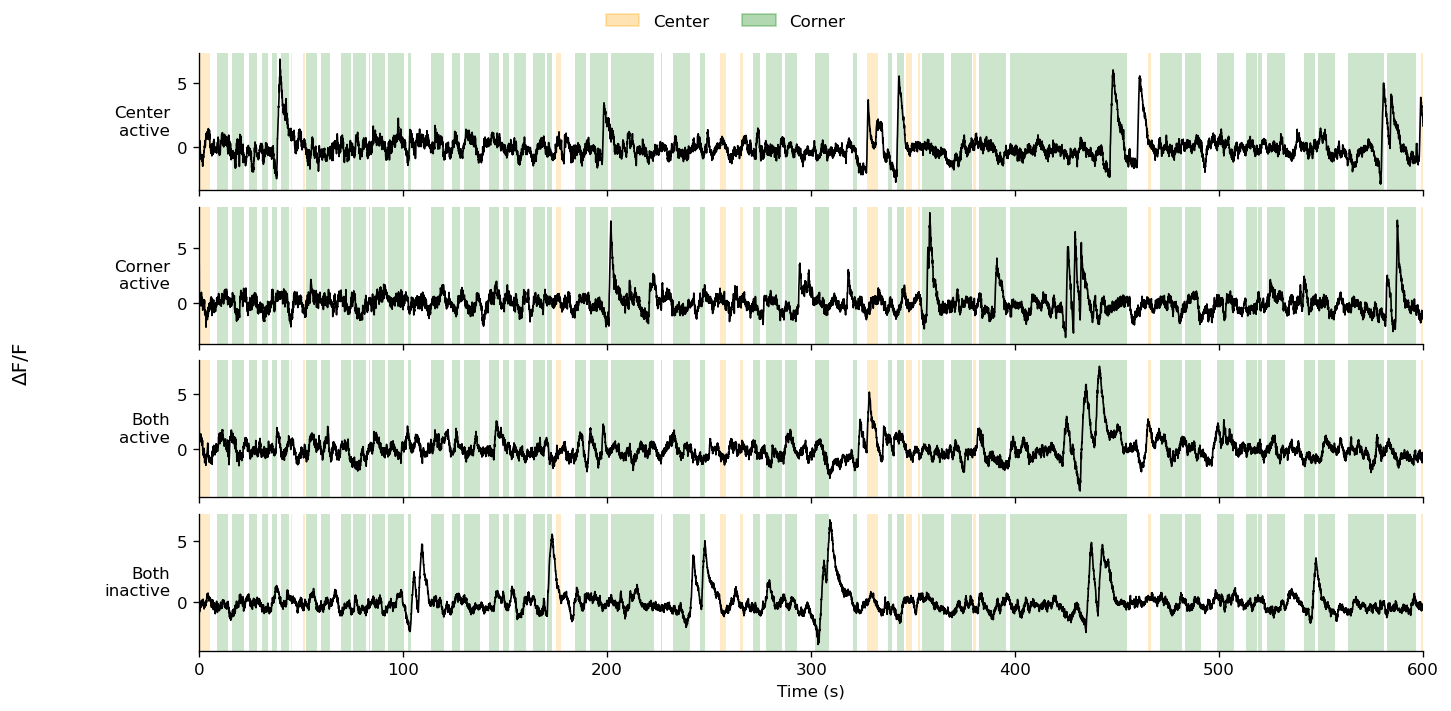

In [3]:
time_s = traces["time_s"].to_numpy(dtype=float)
frame_dt = float(np.nanmedian(np.diff(time_s)))
center_intervals = contiguous_intervals(traces["center"].astype(bool).to_numpy())
corner_intervals = contiguous_intervals(traces["corner"].astype(bool).to_numpy())

fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=True)
fig.subplots_adjust(left=0.14, right=0.99, bottom=0.10, top=0.93, hspace=0.12)
for ax, row in zip(axes, examples.itertuples(index=False)):
    for start, stop in center_intervals:
        ax.axvspan(time_s[start], time_s[stop] + frame_dt, color="orange", alpha=0.22, linewidth=0)
    for start, stop in corner_intervals:
        ax.axvspan(time_s[start], time_s[stop] + frame_dt, color="green", alpha=0.20, linewidth=0)
    ax.plot(time_s, traces[row.neuron], color="black", linewidth=1)
    ax.set_ylabel(row.display_label.replace("-", "\n"), rotation=0, ha="right", va="center")
    ax.margins(x=0)

axes[-1].set_xlabel("Time (s)")
fig.supylabel("ΔF/F", x=0.01)
fig.legend(
    handles=[
        mpl.patches.Patch(color="orange", alpha=0.30, label="Center"),
        mpl.patches.Patch(color="green", alpha=0.30, label="Corner"),
    ],
    loc="upper center",
    ncol=2,
    frameon=False,
)

png_path = save_figure(fig, OUTPUT_DIR / "Fig_3A.png")
plt.show()
